# Shelf-level Forecasting and Inventory Alert System for Corporacion Favorita Sales 

## Import Libraries

In [1]:
# Install py7zr
!pip install py7zr

# Install Google Generative AI package
!pip install -q google-generativeai

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 69.7/69.7 kB 2.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 39.0 MB/s eta 0:00:0000:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.4/96.4 kB 6.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.7/50.7 kB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 141.3/141.3 kB 11.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 428.8/428.8 kB 31.5 MB/s eta 0:00:00


In [2]:
import pandas as pd
import numpy as np
import os
import py7zr
import warnings
warnings.filterwarnings('ignore')

# LLM for Alert Generation
import google.generativeai as genai

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go

# Machine Learning Models
from lightgbm import LGBMRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error

# Time Series Models
from statsmodels.tsa.statespace.sarimax import SARIMAX
from prophet import Prophet

# Deep Learning
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from sklearn.preprocessing import MinMaxScaler

# Suppress warnings
import logging
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'  # 3=error only
logging.getLogger('tensorflow').setLevel(logging.ERROR)

logging.getLogger('prophet').setLevel(logging.ERROR)
logging.getLogger('cmdstanpy').setLevel(logging.ERROR)

logging.getLogger('statsmodels').setLevel(logging.ERROR)

2025-11-17 07:37:14.146669: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1763365034.332110      38 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1763365034.388173      38 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


### Secure API Key Loading

In [3]:
## To load API key from Kaggle Secrets

def load_api_key_secure(secret_name='GEMINI_API_KEY'):
    if 'KAGGLE_KERNEL_RUN_TYPE' in os.environ:
        try:
            from kaggle_secrets import UserSecretsClient
            user_secrets = UserSecretsClient()
            api_key = user_secrets.get_secret(secret_name)
            print(f"Loaded {secret_name} from Kaggle Secrets")
            return api_key
        except Exception as e:
            print(f"Error: {e}")
            return None
    else:
        # Loading from local environment
        from dotenv import load_dotenv
        load_dotenv()
        return os.environ.get(secret_name)


GEMINI_API_KEY = load_api_key_secure('GEMINI_API_KEY')

Loaded GEMINI_API_KEY from Kaggle Secrets


## Load Data

### Create function to import .csv files inside .7z archives

This function loads a single .csv inside a .7z archive directly into a dataframe.

In [4]:
def load_7z_csv(file_path, date_columns=None, parse_dates=False):

    import tempfile
    import os
    
    with tempfile.TemporaryDirectory() as tmpdir:
        with py7zr.SevenZipFile(file_path, mode='r') as archive:
            # Extract all files to temp directory
            archive.extractall(path=tmpdir)
        
        # Find the extracted CSV file
        extracted_files = os.listdir(tmpdir)
        
        if not extracted_files:
            raise ValueError(f"No files found in archive: {file_path}")
        
        # Read the file
        csv_path = os.path.join(tmpdir, extracted_files[0])
    
        
        # Parse dates if requested
        if parse_dates:
            if date_columns is not None:
                df = pd.read_csv(csv_path, parse_dates=date_columns)
            else:
                df = pd.read_csv(csv_path, parse_dates=True)
        else:
            df = pd.read_csv(csv_path)
    
    return df

In [5]:
# test_path = "/kaggle/input/favorita-grocery-sales-forecasting/test.csv.7z"
# test = load_7z_csv(test_path)
# print("Test shape:", test.shape)


train_path = "/kaggle/input/favorita-grocery-sales-forecasting/train.csv.7z"
train = load_7z_csv(train_path, date_columns=['date'], parse_dates=True)
print("Train shape:", train.shape)


items_path = "/kaggle/input/favorita-grocery-sales-forecasting/items.csv.7z"
items = load_7z_csv(items_path)
print("Items shape:", items.shape)

 
holidays_path = "/kaggle/input/favorita-grocery-sales-forecasting/holidays_events.csv.7z"
holidays = load_7z_csv(holidays_path, date_columns=['date'], parse_dates=True)
print("Holiday events shape:", holidays.shape)


oil_path = "/kaggle/input/favorita-grocery-sales-forecasting/oil.csv.7z"
oil = load_7z_csv(oil_path, date_columns=['date'], parse_dates=True)
print("Oil shape:", oil.shape)


stores_path = "/kaggle/input/favorita-grocery-sales-forecasting/stores.csv.7z"
stores = load_7z_csv(stores_path)
print("Stores shape:", stores.shape)


transc_path = "/kaggle/input/favorita-grocery-sales-forecasting/transactions.csv.7z"
transactions = load_7z_csv(transc_path, date_columns=['date'], parse_dates=True)
print("Transactions shape:", transactions.shape)

Train shape: (125497040, 6)
Items shape: (4100, 4)
Holiday events shape: (350, 6)
Oil shape: (1218, 2)
Stores shape: (54, 5)
Transactions shape: (83488, 3)


### Downcast float and integer type columns to lower type

Downcast integer and float columns to smaller dtypes to reduce memory usage

In [6]:
import pandas as pd
import numpy as np

def downcast_dtypes(df, verbose=True):
    start_mem = df.memory_usage().sum() / 1024**2
    
    df_downcasted = df.copy()
    
    for col in df_downcasted.columns:
        col_type = df_downcasted[col].dtype
        
        if pd.api.types.is_integer_dtype(col_type):
            df_downcasted[col] = pd.to_numeric(df_downcasted[col], downcast='integer')
        
        elif pd.api.types.is_float_dtype(col_type):
            df_downcasted[col] = pd.to_numeric(df_downcasted[col], downcast='float')
    
    end_mem = df_downcasted.memory_usage().sum() / 1024**2
    
    if verbose:
        print(f"Memory usage before: {start_mem:.2f} MB")
        print(f"Memory usage after: {end_mem:.2f} MB")
        print(f"Reduced by {100 * (start_mem - end_mem) / start_mem:.1f}%")
    
    return df_downcasted


In [7]:
# Downcast dataframes to lower data type   

# test = downcast_dtypes(test, verbose=True)
train = downcast_dtypes(train, verbose=True)
items = downcast_dtypes(items, verbose=True)
holidays = downcast_dtypes(holidays, verbose=True)
oil = downcast_dtypes(oil, verbose=True)
stores = downcast_dtypes(stores, verbose=True)
transactions = downcast_dtypes(transactions, verbose=True)

Memory usage before: 5744.80 MB
Memory usage after: 3470.82 MB
Reduced by 39.6%
Memory usage before: 0.13 MB
Memory usage after: 0.06 MB
Reduced by 53.1%
Memory usage before: 0.01 MB
Memory usage after: 0.01 MB
Reduced by 0.0%
Memory usage before: 0.02 MB
Memory usage after: 0.01 MB
Reduced by 24.8%
Memory usage before: 0.00 MB
Memory usage after: 0.00 MB
Reduced by 33.0%
Memory usage before: 1.91 MB
Memory usage after: 0.88 MB
Reduced by 54.2%


## Data Preprocessing

### Prepare the Corporacion Favorita Grocery Sales Dataset 

A sample of 10 stores and 10 items is filtered from the entire train dataset by stratified sampling. These item-store pairs will used for training the models and forecasting the sales in the test dataset. 

In [8]:
class FavoritaDataPreparer:

    def sample_items_stores(self, train, items, stores, n_items=10, n_stores=10):
        print("Stratified Sampling....")
        
        ## 1. Stratified sampling of items by family
        print(f"\nSampling {n_items} items across product families...")
        
        # Get item sales by family
        item_sales = train.groupby('item_nbr')['unit_sales'].sum().reset_index()
        item_sales = item_sales.merge(items[['item_nbr', 'family', 'perishable']], on='item_nbr')
        
        # Calculate (proportion) sample size per family 
        family_counts = item_sales['family'].value_counts()
        print(f"\nProduct family distribution in dataset:")
        print(family_counts)
        
        # Sample items proportionally from each family
        sampled_items = []
        for family in family_counts.index:
            family_items = item_sales[item_sales['family'] == family]
            # Calculate proportional sample size
            n_family = max(1, int(n_items * len(family_items) / len(item_sales)))
            # Sample top items by sales within this family
            top_family_items = (family_items
                               .nlargest(n_family, 'unit_sales')['item_nbr']
                               .tolist())
            sampled_items.extend(top_family_items)
        
        # Ensure there are exactly n_items 
        if len(sampled_items) > n_items:
            sampled_items = sampled_items[:n_items]
        elif len(sampled_items) < n_items:
            # Fill remaining with items not yet included
            remaining = item_sales[~item_sales['item_nbr'].isin(sampled_items)]
            additional = remaining.nlargest(n_items - len(sampled_items), 'unit_sales')['item_nbr'].tolist()
            sampled_items.extend(additional)
        
        print(f"\nSampled {len(sampled_items)} items across {item_sales[item_sales['item_nbr'].isin(sampled_items)]['family'].nunique()} families")
        
        ## 2. Stratified sampling of stores by cluster
        print(f"\nSampling {n_stores} stores across clusters...")
        
        # Get store sales by cluster
        store_sales = train.groupby('store_nbr')['unit_sales'].sum().reset_index()
        store_sales = store_sales.merge(stores[['store_nbr', 'cluster', 'city', 'type']], on='store_nbr')
        
        # Sample stores proportionally from each cluster
        cluster_counts = stores['cluster'].value_counts()
        print(f"\nStore cluster distribution:")
        print(cluster_counts)
        
        sampled_stores = []
        for cluster in cluster_counts.index:
            cluster_stores = store_sales[store_sales['cluster'] == cluster]
            n_cluster = max(1, int(n_stores * len(cluster_stores) / len(store_sales)))
            top_cluster_stores = (cluster_stores
                                 .nlargest(n_cluster, 'unit_sales')['store_nbr']
                                 .tolist())
            sampled_stores.extend(top_cluster_stores)
        
        # Select exactly n_stores
        if len(sampled_stores) > n_stores:
            sampled_stores = sampled_stores[:n_stores]
        elif len(sampled_stores) < n_stores:
            remaining = store_sales[~store_sales['store_nbr'].isin(sampled_stores)]
            additional = remaining.nlargest(n_stores - len(sampled_stores), 'unit_sales')['store_nbr'].tolist()
            sampled_stores.extend(additional)
        
        print(f"\nSampled {len(sampled_stores)} stores across {store_sales[store_sales['store_nbr'].isin(sampled_stores)]['cluster'].nunique()} clusters")
        
        train_filtered = train[
            (train['item_nbr'].isin(sampled_items)) & 
            (train['store_nbr'].isin(sampled_stores))
        ].copy()
        
        print(f"\nFiltered data shape: {train_filtered.shape}")
        print(f"Date range: {train_filtered['date'].min()} to {train_filtered['date'].max()}")
        
        return train_filtered, sampled_items, sampled_stores

    def filter_last_2years(self, df):
        df['year'] = df['date'].dt.year
        df_filtered = df[df['year'].isin([2016, 2017])].copy()
        print(f"\nFiltered to 2016-2017: {df_filtered.shape}")
        return df_filtered


In [9]:
preparer = FavoritaDataPreparer()
train_filtered, top_items, top_stores = preparer.sample_items_stores(train, items, stores)
train_filtered = preparer.filter_last_2years(train_filtered)

Stratified Sampling....

Sampling 10 items across product families...

Product family distribution in dataset:
family
GROCERY I                     1290
BEVERAGES                      604
CLEANING                       446
PRODUCE                        306
DAIRY                          242
PERSONAL CARE                  153
BREAD/BAKERY                   134
HOME CARE                      108
DELI                            91
MEATS                           84
HOME AND KITCHEN I              77
LIQUOR,WINE,BEER                63
FROZEN FOODS                    55
POULTRY                         54
HOME AND KITCHEN II             45
EGGS                            41
CELEBRATION                     31
LAWN AND GARDEN                 26
PREPARED FOODS                  26
LADIESWEAR                      21
LINGERIE                        20
AUTOMOTIVE                      20
BEAUTY                          19
PLAYERS AND ELECTRONICS         17
SCHOOL AND OFFICE SUPPLIES      15
PET SUP

### Perform data quality checks and cleaning

In [10]:
class DataQualityChecker:

    @staticmethod
    def check_and_clean(df):
        print("\nCheck Data Quality....")

        print("\nMissing values:")
        print(df.isna().sum())

        negative_sales = (df['unit_sales'] < 0).sum()
        print(f"\nNegative sales: {negative_sales} ({negative_sales/len(df)*100:.2f}%)")
        df['unit_sales'] = df['unit_sales'].clip(lower=0)

        if "onpromotion" in df.columns:
            df['onpromotion'] = df['onpromotion'].fillna(False)

        q99 = df['unit_sales'].quantile(0.99)
        outliers = (df['unit_sales'] > q99).sum()
        print(f"Outliers (>99th percentile): {outliers} ({outliers/len(df)*100:.2f}%)")

        return df

In [11]:
# Perform data quality checks
checker = DataQualityChecker()
train_filtered = checker.check_and_clean(train_filtered)

# Create a copy of the filtered train dataset to be used for training SARIMA, LSTM, Prophet
train_for_sarima_lstm_prophet = train_filtered.copy()


Check Data Quality....

Missing values:
id             0
date           0
store_nbr      0
item_nbr       0
unit_sales     0
onpromotion    0
year           0
dtype: int64

Negative sales: 1 (0.00%)
Outliers (>99th percentile): 562 (1.00%)


### Exploratory Data Analysis

In [12]:
class EDAAnalyzer:

    @staticmethod
    def analyze_sales_trends(df, items_df=None):
        print("\nSales Trends Analysis....")
        
        if items_df is not None:
            df = df.merge(items_df[['item_nbr', 'family']], on='item_nbr', how='left')
        
        # Analyze if family column exists
        if 'family' in df.columns:
            # Sales by family
            family_sales = df.groupby('family')['unit_sales'].agg(['sum', 'mean', 'count'])
            print("\nTop 5 families by total sales:")
            print(family_sales.sort_values('sum', ascending=False).head())
        
        # Time trends
        daily_sales = df.groupby('date')['unit_sales'].sum()
        print(f"\nAverage daily sales: {daily_sales.mean():.2f}")
        print(f"Std deviation: {daily_sales.std():.2f}")
        
        return df
    
    @staticmethod
    def analyze_seasonality(df):
        print("\nSeasonality Analysis.... ")
        
        # Create temporary columns for analysis only
        df_temp = df.copy()
        df_temp['dow'] = df_temp['date'].dt.dayofweek
        df_temp['month'] = df_temp['date'].dt.month
        
        # Weekly pattern
        weekly_pattern = df_temp.groupby('dow')['unit_sales'].mean()
        print("\nAverage sales by day of week:")
        days = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
        for i, day in enumerate(days):
            print(f"  {day}: {weekly_pattern[i]:.2f}")
        
        # Monthly pattern
        monthly_pattern = df_temp.groupby('month')['unit_sales'].mean()
        print("\nAverage sales by month:")
        months = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 
                 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
        for i, month in enumerate(months, 1):
            if i in monthly_pattern.index:
                print(f"  {month}: {monthly_pattern[i]:.2f}")
        
        return df
    
    @staticmethod
    def analyze_promotions(df):
        if 'onpromotion' not in df.columns:
            print("\nPromotional Impact...")
            print("No promotion data available")
            return df
            
        print("\nPromotional Impact....")
        
        promo_impact = df.groupby('onpromotion')['unit_sales'].agg(['mean', 'median', 'count'])
        print("\nSales: Promotion vs No Promotion")
        print(promo_impact)
        
        if True in promo_impact.index and False in promo_impact.index:
            lift = (promo_impact.loc[True, 'mean'] / promo_impact.loc[False, 'mean'] - 1) * 100
            print(f"\nPromotional lift: {lift:.2f}%")
            
            promo_pct = promo_impact.loc[True, 'count'] / promo_impact['count'].sum() * 100
            print(f"Percentage of sales on promotion: {promo_pct:.1f}%")
        
        return df

In [13]:
# Perform EDA
eda = EDAAnalyzer()
train_filtered = eda.analyze_sales_trends(train_filtered, items)
train_filtered = eda.analyze_seasonality(train_filtered)
train_filtered = eda.analyze_promotions(train_filtered)


Sales Trends Analysis....

Top 5 families by total sales:
                    sum        mean  count
family                                    
GROCERY I     1099061.0   62.273273  17649
PRODUCE       1090668.0  286.640747   3805
BEVERAGES      691004.0  118.566231   5828
DAIRY          325045.0   58.991833   5510
BREAD/BAKERY   314374.0   53.292763   5899

Average daily sales: 6537.12
Std deviation: 1617.93

Seasonality Analysis.... 

Average sales by day of week:
  Monday: 66.52
  Tuesday: 60.06
  Wednesday: 67.41
  Thursday: 53.78
  Friday: 61.24
  Saturday: 80.70
  Sunday: 91.12

Average sales by month:
  Jan: 72.84
  Feb: 66.75
  Mar: 69.25
  Apr: 73.58
  May: 65.22
  Jun: 65.83
  Jul: 66.67
  Aug: 67.08
  Sep: 68.59
  Oct: 67.59
  Nov: 65.82
  Dec: 76.71

Promotional Impact....

Sales: Promotion vs No Promotion
                  mean  median  count
onpromotion                          
False        66.824768    34.0  49371
True         82.195198    36.0   6785

Promotional lift:

## Feature Engineering

### Define a class to create new features for demand forecasting

In [14]:
class FeatureEngineer:

    @staticmethod
    def merge_items_data(df, items):
        print("\nMerging items data...")
        
        df = df.merge(items[['item_nbr', 'family', 'class', 'perishable']], 
                      on=['item_nbr','family'], how='left')
        
        df['family_encoded'] = pd.factorize(df['family'])[0]
        df['class_encoded'] = pd.factorize(df['class'])[0]
        df['perishable'] = df['perishable'].fillna(0).astype(int)
        
        print(f"Added item features: family, class, perishable")
        print(f"Unique families: {df['family'].nunique()}")
        print(f"Perishable items: {df['perishable'].sum()} ({df['perishable'].sum()/len(df)*100:.2f}%)")
        
        return df

    @staticmethod
    def merge_stores_data(df, stores):
        print("\nMerging stores data...")
        
        df = df.merge(stores[['store_nbr', 'city', 'state', 'type', 'cluster']],
                     on='store_nbr', how='left')
        
        df['city_encoded'] = pd.factorize(df['city'])[0]
        df['state_encoded'] = pd.factorize(df['state'])[0]
        df['type_encoded'] = pd.factorize(df['type'])[0]
        df['store_cluster'] = df['cluster'].fillna(0).astype(int)
        
        print(f"Added store features: city, state, type, cluster")
        print(f"Unique cities: {df['city'].nunique()}")
        print(f"Store types: {df['type'].nunique()}")
        
        return df

    @staticmethod
    def merge_holidays_data(df, holidays):
        print("\nMerging holidays data...")
        
        holidays = holidays.copy()
        holidays['date'] = pd.to_datetime(holidays['date'])
        holidays['is_holiday'] = 1
        
        national_holidays = holidays[holidays['locale']=='National'][['date', 'is_holiday']]
        national_holidays = national_holidays.rename(columns={'is_holiday':'is_national_holiday'})
        
        regional_holidays = holidays[holidays['locale']=='Regional'][['date', 'is_holiday']]
        regional_holidays = regional_holidays.rename(columns={'is_holiday':'is_regional_holiday'})
        
        local_holidays = holidays[holidays['locale']=='Local'][['date', 'is_holiday']]
        local_holidays = local_holidays.rename(columns={'is_holiday':'is_local_holiday'})
        
        df = (df.merge(national_holidays, on='date', how='left')
                .merge(regional_holidays, on='date', how='left')
                .merge(local_holidays, on='date', how='left'))
        
        df['is_national_holiday'] = df['is_national_holiday'].fillna(0).astype(int)
        df['is_regional_holiday'] = df['is_regional_holiday'].fillna(0).astype(int)
        df['is_local_holiday'] = df['is_local_holiday'].fillna(0).astype(int)
        df['is_any_holiday'] = (df['is_national_holiday'] | df['is_regional_holiday'] | df['is_local_holiday']).astype(int)
        
        df = df.sort_values('date')
        holiday_dates = df[df['is_any_holiday'] == 1]['date'].unique()
        
        def days_to_nearest_holiday(date, holiday_dates):
            if len(holiday_dates) == 0:
                return 30
            diffs = (holiday_dates - date).days
            future_diffs = diffs[diffs >= 0]
            past_diffs = diffs[diffs < 0]
            
            if len(future_diffs) > 0:
                return future_diffs.min()
            elif len(past_diffs) > 0:
                return past_diffs.max()
            return 30
        
        df['days_to_holiday'] = df['date'].apply(lambda x: days_to_nearest_holiday(x, holiday_dates))
        df['days_to_holiday'] = df['days_to_holiday'].clip(-30, 30)
        
        print(f"Holiday dates: {len(holiday_dates)}")
        print(f"National holidays: {df['is_national_holiday'].sum()}")
        
        return df

    @staticmethod
    def merge_oil_data(df, oil):
        print("\nMerging oil price data...")
        
        oil = oil.copy()
        oil = oil.sort_values('date')
        
        oil['dcoilwtico'] = oil['dcoilwtico'].ffill().bfill()
        oil['oil_price_7d_change'] = oil['dcoilwtico'].diff(7)
        oil['oil_price_30d_change'] = oil['dcoilwtico'].diff(30)
        oil['oil_price_ma_7'] = oil['dcoilwtico'].rolling(window=7, min_periods=1).mean()
        oil['oil_price_ma_30'] = oil['dcoilwtico'].rolling(window=30, min_periods=1).mean()
        
        df = df.merge(oil, on='date', how='left')
        
        df['dcoilwtico'] = df['dcoilwtico'].fillna(df['dcoilwtico'].median())
        df['oil_price_7d_change'] = df['oil_price_7d_change'].fillna(0)
        df['oil_price_30d_change'] = df['oil_price_30d_change'].fillna(0)
        df['oil_price_ma_7'] = df['oil_price_ma_7'].fillna(df['dcoilwtico'])
        df['oil_price_ma_30'] = df['oil_price_ma_30'].fillna(df['dcoilwtico'])
        
        print(f"Oil price range: ${df['dcoilwtico'].min():.2f} - ${df['dcoilwtico'].max():.2f}")
        
        return df

    @staticmethod
    def merge_transactions_data(df, transactions):
        print("\nMerging transactions data...")
        
        df = df.merge(transactions, on=['date', 'store_nbr'], how='left')
        df['transactions'] = df['transactions'].fillna(df['transactions'].median())
        
        df = df.sort_values(['store_nbr', 'date'])
        df['transactions_lag_7'] = df.groupby('store_nbr')['transactions'].shift(7)
        df['transactions_growth'] = (df['transactions'] - df['transactions_lag_7']) / df['transactions_lag_7']
        df['transactions_growth'] = df['transactions_growth'].fillna(0).clip(-1, 1)
        
        print(f"Average daily transactions per store: {df['transactions'].mean():.0f}")
        
        return df

    @staticmethod
    def create_temporal_features(df):
        print("\nCreating temporal features...")
        
        df['dow'] = df['date'].dt.dayofweek
        df['day'] = df['date'].dt.day
        df['month'] = df['date'].dt.month
        df['year'] = df['date'].dt.year
        df['quarter'] = df['date'].dt.quarter
        df['is_weekend'] = df['dow'].isin([5, 6]).astype(int)
        df['is_month_start'] = df['date'].dt.is_month_start.astype(int)
        df['is_month_end'] = df['date'].dt.is_month_end.astype(int)
        df['week_of_year'] = df['date'].dt.isocalendar().week
        
        return df

    @staticmethod
    def create_lag_features(df, lags=[1, 7, 14, 30]):
        print("\nCreating lag features...")
        
        df = df.sort_values(['item_nbr', 'store_nbr', 'date'])
        
        for lag in lags:
            df[f'sales_lag_{lag}'] = (
                df.groupby(['item_nbr', 'store_nbr'])['unit_sales']
                .shift(lag)
            )
        
        return df
    
    @staticmethod
    def create_rolling_features(df, windows=[7, 14, 30]):
        print("\nCreating rolling features...")
        
        df = df.sort_values(['item_nbr', 'store_nbr', 'date'])
        
        for window in windows:
            # Shift by 1 to prevent data leakage
            df[f'sales_ma_{window}'] = (
                df.groupby(['item_nbr', 'store_nbr'])['unit_sales']
                .transform(lambda x: x.rolling(window=window, min_periods=1).mean().shift(1))
            )
            
            df[f'sales_std_{window}'] = (
                df.groupby(['item_nbr', 'store_nbr'])['unit_sales']
                .transform(lambda x: x.rolling(window=window, min_periods=1).std().shift(1))
            )
        
        return df
        
    @staticmethod
    def create_promotional_features(df):
        if 'onpromotion' not in df.columns:
            return df
            
        print("\nCreating promotional features...")
        
        df['onpromotion'] = df['onpromotion'].astype(int)
        df['promo_lag_1'] = df.groupby(['item_nbr', 'store_nbr'])['onpromotion'].shift(1)
        df['promo_lag_7'] = df.groupby(['item_nbr', 'store_nbr'])['onpromotion'].shift(7)
        
        return df

    @staticmethod
    def create_interaction_features(df):
        print("\nCreating interaction features...")
        
        if 'perishable' in df.columns and 'is_any_holiday' in df.columns:
            df['perishable_holiday_interaction'] = df['perishable'] * df['is_any_holiday']
        
        if 'is_weekend' in df.columns and 'type_encoded' in df.columns:
            df['weekend_store_type'] = df['is_weekend'] * df['type_encoded']
        
        if 'onpromotion' in df.columns and 'is_any_holiday' in df.columns:
            df['promo_holiday_interaction'] = df['onpromotion'].astype(int) * df['is_any_holiday']
        
        if 'dcoilwtico' in df.columns and 'family_encoded' in df.columns:
            df['oil_family_interaction'] = df['dcoilwtico'] * df['family_encoded']
        
        return df
        
    @staticmethod
    def create_all_features(df, items, stores, holidays, oil, transactions):
        print("\n==== Feature Engineering ====")
        
        df = FeatureEngineer.merge_items_data(df, items)
        df = FeatureEngineer.merge_stores_data(df, stores)
        df = FeatureEngineer.merge_holidays_data(df, holidays)
        df = FeatureEngineer.merge_oil_data(df, oil)
        df = FeatureEngineer.merge_transactions_data(df, transactions)
        df = FeatureEngineer.create_temporal_features(df)
        df = FeatureEngineer.create_lag_features(df)
        df = FeatureEngineer.create_rolling_features(df)
        df = FeatureEngineer.create_promotional_features(df)
        df = FeatureEngineer.create_interaction_features(df)
        
        print(f"\nShape before dropna: {df.shape}")
        df = df.dropna()
        print(f"Shape after dropna: {df.shape}")
        
        print("\nFeature Summary...")
        print(f"Total features: {len(df.columns)}")
        
        return df

In [15]:
## Perform feature engineering
engineer = FeatureEngineer()
train_featured = engineer.create_all_features(train_filtered, items=items, stores=stores, holidays=holidays, oil=oil, transactions=transactions)

# Split data into train and test 
all_dates = sorted(train_featured['date'].unique())
split_index = int(len(all_dates) * 0.8)
split_date = all_dates[split_index]
train_data = train_featured[train_featured['date']<=split_date]
test_data = train_featured[train_featured['date'] > split_date]

# Filter test_data to only include sampled 10 items and 10 stores
print(f"\nBefore filtering - Test data shape: {test_data.shape}")
test_data = test_data[
    (test_data['item_nbr'].isin(top_items)) & 
    (test_data['store_nbr'].isin(top_stores))
]
print(f"After filtering - Test data shape: {test_data.shape}")

print(f"\nTrain set: {train_data.shape}")
print(f"Test set: {test_data.shape}")


==== Feature Engineering ====

Merging items data...
Added item features: family, class, perishable
Unique families: 8
Perishable items: 15214 (27.09%)

Merging stores data...
Added store features: city, state, type, cluster
Unique cities: 6
Store types: 5

Merging holidays data...
Holiday dates: 98
National holidays: 6145

Merging oil price data...
Oil price range: $26.19 - $54.48

Merging transactions data...
Average daily transactions per store: 2283

Creating temporal features...

Creating lag features...

Creating rolling features...

Creating promotional features...

Creating interaction features...

Shape before dropna: (56913, 57)
Shape after dropna: (54000, 57)

Feature Summary...
Total features: 57

Before filtering - Test data shape: (10731, 57)
After filtering - Test data shape: (10731, 57)

Train set: (43269, 57)
Test set: (10731, 57)


In [16]:
# Prepare train and test datasets for machine learning models
feature_cols = [col for col in train_data.columns 
               if col not in ['date', 'unit_sales', 'item_nbr', 'store_nbr', 'year']]

X_train = train_data[feature_cols]
y_train = train_data['unit_sales']

# For lgbm
X_test_lgbm = test_data[feature_cols].copy()

# For time series models
X_test_ts = test_data[['date', 'item_nbr', 'store_nbr']].copy()

y_test = test_data['unit_sales']

## Model Training for Demand Forecasting

### Create a class to predict sales using LGBM model

In [17]:
class LightGBMForecaster:
    
    def __init__(self):
        self.model = None
        self.features = [
            'dow', 'month', 'is_weekend', 'quarter', 'week_of_year',
            'is_month_start', 'is_month_end',
            'sales_lag_1', 'sales_lag_7', 'sales_lag_14', 'sales_lag_30',
            'sales_ma_7', 'sales_ma_14', 'sales_ma_30',
            'sales_std_7', 'sales_std_14', 'sales_std_30',
            'family_encoded', 'class_encoded', 'perishable',
            'store_cluster', 'type_encoded', 'city_encoded', 'state_encoded',
            'is_national_holiday', 'is_regional_holiday', 'is_local_holiday',
            'is_any_holiday', 'days_to_holiday',
            'dcoilwtico', 'oil_price_7d_change', 'oil_price_30d_change',
            'oil_price_ma_7', 'oil_price_ma_30',
            'transactions', 'transactions_growth',
            'onpromotion', 'promo_lag_1', 'promo_lag_7',
            'perishable_holiday_interaction', 'weekend_store_type',
            'promo_holiday_interaction', 'oil_family_interaction'
        ]
    
    def train(self, X_train, y_train):
        print("\nTraining LightGBM....")
        
        self.model = LGBMRegressor(
            n_estimators=200,
            learning_rate=0.1,
            max_depth=6,
            num_leaves=31,
            feature_fraction=0.8,
            bagging_fraction=0.8,
            bagging_freq=5,
            random_state=42,
            verbose=-1
        )
        
        available_features = [f for f in self.features if f in X_train.columns]
        self.model.fit(X_train[available_features], y_train)
        
        importance = pd.DataFrame({
            'feature': available_features,
            'importance': self.model.feature_importances_
        }).sort_values('importance', ascending=False)
        
        print("\nTOP 10 Most Important Features")
        print(importance.head(10).to_string(index=False))
        
        return self
    
    def predict(self, X_test):
        available_features = [f for f in self.features if f in X_test.columns]
        return self.model.predict(X_test[available_features])

### Create a class to forecast sales using SARIMA

In [18]:
class SARIMAForecaster:

    def __init__(self, order=(1, 1, 1), seasonal_order=(1, 1, 1, 7)):
        self.order = order
        self.seasonal_order = seasonal_order
        self.models = {}
        self.trained_pairs = []

    def train(self, df, item_store_pairs=None):
        print("\n Training SARIMA....")

        if item_store_pairs is None:
            top_pairs = (df.groupby(['item_nbr', 'store_nbr'])['unit_sales']
                         .sum()
                         .index.tolist())
            item_store_pairs = top_pairs
        
        self.trained_pairs = item_store_pairs

        for item, store in self.trained_pairs:
            try:
                series = df[(df['item_nbr'] == item) & (df['store_nbr'] == store)]
                series = series.set_index('date')['unit_sales'].sort_index()

                model = SARIMAX(series,
                                order=self.order,
                                seasonal_order=self.seasonal_order,
                                enforce_stationarity=False,
                                enforce_invertibility=False)

                fitted_model = model.fit(disp=False)
                self.models[(item, store)] = fitted_model

            except Exception as e:
                print(f"Failed for item {item}, store {store}: {str(e)}")
                continue

        return self

    def predict(self, X_test):

        # Create an empty series with the same index as X_test
        predictions = pd.Series(np.nan, index=X_test.index)
        
        # Find the forecast horizon (e.g., 7 days)
        test_dates = sorted(X_test['date'].unique())
        n_steps = len(test_dates)
        
        if n_steps == 0:
            return predictions # Return empty if X_test is empty

        for (item, store), model in self.models.items():
            try:
                # Generate N-step forecast
                forecast_values = model.forecast(steps=n_steps).values
                
                # Create a temporary series mapping dates to forecast values
                forecast_series = pd.Series(forecast_values, index=test_dates)

                # Find the rows in X_test that match this item/store
                idx = X_test[(X_test['item_nbr'] == item) & (X_test['store_nbr'] == store)].index
                
                if not idx.empty:
                    # Get the dates for these specific rows
                    dates_for_idx = X_test.loc[idx, 'date']
                    # Map the dates to the forecasted values
                    aligned_values = dates_for_idx.map(forecast_series)
                    # Assign these values to our main predictions series
                    predictions.loc[idx] = aligned_values.values

            except Exception as e:
                print(f"Prediction failed for SARIMA item {item}, store {store}: {str(e)}")
                continue

        return predictions

### Create a class to forecast sales using Prophet

In [19]:
class ProphetForecaster:

    def __init__(self):
        self.models = {}

    def train(self, df, item_store_pairs=None):
        print("\nTraining Prophet....")

        if item_store_pairs is None:
            top_pairs = (df.groupby(['item_nbr', 'store_nbr'])['unit_sales']
                         .sum()
                         .index.tolist())
            item_store_pairs = top_pairs

        for item, store in item_store_pairs:  
            try:
                series = df[(df['item_nbr'] == item) & (df['store_nbr'] == store)]

                # Prepare data for Prophet
                prophet_df = pd.DataFrame({
                    'ds': series['date'],
                    'y': series['unit_sales']
                })

                model = Prophet(
                    daily_seasonality=True,
                    weekly_seasonality=True,
                    yearly_seasonality=True,
                    changepoint_prior_scale=0.05
                )

                model.fit(prophet_df)
                self.models[(item, store)] = model

            except Exception as e:
                print(f"Failed for item {item}, store {store}: {str(e)}")
                continue

        return self

    def predict(self, X_test):
        # Create an empty series with the same index as X_test
        predictions = pd.Series(np.nan, index=X_test.index)

        for (item, store), model in self.models.items():
            try:
                # Find the rows in X_test that match this item/store
                idx = X_test[(X_test['item_nbr'] == item) & (X_test['store_nbr'] == store)].index

                if idx.empty:
                    continue
                
                # Create the future dataframe for Prophet
                future_df = X_test.loc[idx, ['date']].rename(columns={'date': 'ds'})

                # Generate forecast
                forecast = model.predict(future_df)
                
                # Assign the yhat values to our main predictions series
                predictions.loc[idx] = forecast['yhat'].values

            except Exception as e:
                print(f"Prediction failed for Prophet item {item}, store {store}: {str(e)}")
                continue
                
        return predictions

### Create a class to forecast sales using LSTM

In [20]:
class LSTMForecaster:

    def __init__(self, sequence_length=30):
        self.sequence_length = sequence_length
        self.model = None
        self.models = {}  # Stores model and scaler for each pair

    def prepare_sequences(self, data):
        X, y = [], []

        for i in range(len(data) - self.sequence_length):
            X.append(data[i:i + self.sequence_length])
            y.append(data[i + self.sequence_length])

        return np.array(X), np.array(y)

    # To build LSTM architecture
    def build_model(self, input_shape):
        model = Sequential([
            LSTM(50, activation='relu', return_sequences=True, input_shape=input_shape),
            Dropout(0.2),
            LSTM(50, activation='relu'),
            Dropout(0.2),
            Dense(25, activation='relu'),
            Dense(1)
        ])

        model.compile(optimizer='adam', loss='mse', metrics=['mae'])
        return model

    def train(self, df, item_store_pairs=None):
        print("\nTraining LSTM....")

        if item_store_pairs is None:
            top_pairs = (df.groupby(['item_nbr', 'store_nbr'])['unit_sales']
                         .sum()
                         .index.tolist())
            item_store_pairs = top_pairs

        for item, store in item_store_pairs: 
            try:
                series = df[(df['item_nbr'] == item) & (df['store_nbr'] == store)]
                series_values = series.sort_values('date')['unit_sales'].values.reshape(-1, 1)

                # Scale data
                scaler = MinMaxScaler()
                scaled_data = scaler.fit_transform(series_values)

                # Prepare sequences
                X, y = self.prepare_sequences(scaled_data)

                if len(X) < 50:  # Skip if not enough data
                    print(f"Skipping LSTM for item {item}, store {store}: not enough data")
                    continue

                # Reshape for LSTM
                X = X.reshape((X.shape[0], X.shape[1], 1))

                # Build and train model
                model = self.build_model((X.shape[1], 1))
                model.fit(X, y, epochs=20, batch_size=32, verbose=0)

                self.models[(item, store)] = {
                    'model': model,
                    'scaler': scaler,
                    'last_sequence': scaled_data[-self.sequence_length:] # Store last known seq
                }

                # print(f"Trained LSTM for item {item}, store {store}")

            except Exception as e:
                print(f"Failed for item {item}, store {store}: {str(e)}")
                continue

        return self

    def predict(self, X_test):
        predictions = pd.Series(np.nan, index=X_test.index)
        
        test_dates = sorted(X_test['date'].unique())
        n_steps = len(test_dates)
        
        if n_steps == 0:
            return predictions

        for (item, store), model_dict in self.models.items():
            try:
                model = model_dict['model']
                scaler = model_dict['scaler']
                
                # Multi-step prediction
                forecast_values_scaled = []
                current_seq = model_dict['last_sequence'].reshape(1, self.sequence_length, 1)

                for _ in range(n_steps):
                    pred_scaled = model.predict(current_seq, verbose=0)
                    forecast_values_scaled.append(pred_scaled[0, 0])

                    # Update sequence
                    current_seq = np.append(current_seq[:, 1:, :],
                                            pred_scaled.reshape(1, 1, 1), axis=1)

                # Inverse transform
                forecast_values = scaler.inverse_transform(np.array(forecast_values_scaled).reshape(-1, 1)).flatten()

                # Align with X_test index as in SARIMA
                forecast_series = pd.Series(forecast_values, index=test_dates)
                idx = X_test[(X_test['item_nbr'] == item) & (X_test['store_nbr'] == store)].index
                
                if not idx.empty:
                    dates_for_idx = X_test.loc[idx, 'date']
                    aligned_values = dates_for_idx.map(forecast_series)
                    predictions.loc[idx] = aligned_values.values

            except Exception as e:
                print(f"Prediction failed for LSTM item {item}, store {store}: {str(e)}")
                continue

        return predictions

## Model Evaluation

### Create a class to evaluate the forecasting models

In [21]:
# Ensure inputs are numpy arrays for masking
class ModelEvaluator:
    
    @staticmethod
    def calculate_metrics(y_true, y_pred):

        y_true = np.array(y_true)
        y_pred = np.array(y_pred)
        
        valid_mask = ~np.isnan(y_pred)
        if np.sum(valid_mask) == 0:
            print("Warning: No valid predictions to evaluate.")
            return {'MAE': np.nan, 'RMSE': np.nan, 'MAPE': np.nan}
        
        y_true = y_true[valid_mask]
        y_pred = y_pred[valid_mask]
        
        mae = mean_absolute_error(y_true, y_pred)
        rmse = np.sqrt(mean_squared_error(y_true, y_pred))
        
        zero_mask = y_true != 0
        if np.sum(zero_mask) == 0:
            mape = np.nan
        else:
            mape = np.mean(np.abs((y_true[zero_mask] - y_pred[zero_mask]) / y_true[zero_mask])) * 100
        
        return {
            'MAE': mae,
            'RMSE': rmse,
            'MAPE': mape
        }
    
    @staticmethod
    def evaluate_model(model_name, y_true, y_pred):
        print(f"\n=== {model_name} Performance ===")
        
        metrics = ModelEvaluator.calculate_metrics(y_true, y_pred)
        
        for metric, value in metrics.items():
            print(f"{metric}: {value:.3f}")
        
        return metrics

    @staticmethod
    def compare_models(results_dict):
        print("\nModel Comparison")

        comparison = pd.DataFrame(results_dict).T
        print(comparison)

        # Best model by MAPE
        try:
            best_model = comparison['MAPE'].idxmin()
            print(f"\nBest model by MAPE: {best_model}")
        except:
            print("\nCould not determine best model by MAPE (all-NaN?).")

        return comparison

### Train and Evaluate the Models

In [22]:
## Train the models on engineered train dataset

lgbm_forecaster = LightGBMForecaster().train(X_train, y_train)

# Train SARIMA, Prophet and LSTM on the filtered train dataset
sarima_forecaster = SARIMAForecaster().train(train_for_sarima_lstm_prophet)
prophet_forecaster = ProphetForecaster().train(train_for_sarima_lstm_prophet)
lstm_forecaster = LSTMForecaster().train(train_for_sarima_lstm_prophet)

# Generate all predictions
lgb_pred = lgbm_forecaster.predict(X_test_lgbm)
sarima_pred = sarima_forecaster.predict(X_test_ts)
prophet_pred = prophet_forecaster.predict(X_test_ts)
lstm_pred = lstm_forecaster.predict(X_test_ts)

# Convert lgb_pred (array) to a series
lgb_pred = pd.Series(lgb_pred, index=y_test.index)


# Evaluate models
results = {}
results['LGBM'] = ModelEvaluator.evaluate_model("LGBM", y_test, lgb_pred)
results['SARIMA'] = ModelEvaluator.evaluate_model("SARIMA", y_test, sarima_pred)
results['Prophet'] = ModelEvaluator.evaluate_model("Prophet", y_test, prophet_pred)
results['LSTM'] = ModelEvaluator.evaluate_model("LSTM", y_test, lstm_pred)


## Final Comparison
ModelEvaluator.compare_models(results)


Training LightGBM....

TOP 10 Most Important Features
            feature  importance
        sales_lag_1         394
       sales_lag_14         382
       transactions         332
        sales_std_7         324
        sales_lag_7         302
       sales_lag_30         300
transactions_growth         218
        sales_ma_30         215
         sales_ma_7         211
oil_price_7d_change         210

 Training SARIMA....


/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)



Training Prophet....


07:42:01 - cmdstanpy - INFO - Chain [1] done processing
07:42:01 - cmdstanpy - INFO - Chain [1] start processing
07:42:01 - cmdstanpy - INFO - Chain [1] done processing
07:42:01 - cmdstanpy - INFO - Chain [1] start processing
07:42:01 - cmdstanpy - INFO - Chain [1] done processing
07:42:01 - cmdstanpy - INFO - Chain [1] start processing
07:42:01 - cmdstanpy - INFO - Chain [1] done processing
07:42:01 - cmdstanpy - INFO - Chain [1] start processing
07:42:01 - cmdstanpy - INFO - Chain [1] done processing
07:42:01 - cmdstanpy - INFO - Chain [1] start processing
07:42:01 - cmdstanpy - INFO - Chain [1] done processing
07:42:01 - cmdstanpy - INFO - Chain [1] start processing
07:42:01 - cmdstanpy - INFO - Chain [1] done processing
07:42:01 - cmdstanpy - INFO - Chain [1] start processing
07:42:01 - cmdstanpy - INFO - Chain [1] done processing
07:42:01 - cmdstanpy - INFO - Chain [1] start processing
07:42:01 - cmdstanpy - INFO - Chain [1] done processing
07:42:01 - cmdstanpy - INFO - Chain [1] 

Failed for item 1503844, store 40: Dataframe has less than 2 non-NaN rows.

Training LSTM....


I0000 00:00:1763365329.509851      38 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 15513 MB memory:  -> device: 0, name: Tesla P100-PCIE-16GB, pci bus id: 0000:00:04.0, compute capability: 6.0
I0000 00:00:1763365335.388171     213 service.cc:148] XLA service 0x7d6e4c00c270 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1763365335.388799     213 service.cc:156]   StreamExecutor device (0): Tesla P100-PCIE-16GB, Compute Capability 6.0
I0000 00:00:1763365335.951272     213 cuda_dnn.cc:529] Loaded cuDNN version 90300
I0000 00:00:1763365338.050561     213 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


Skipping LSTM for item 1503844, store 19: not enough data
Skipping LSTM for item 1503844, store 40: not enough data


/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa


=== LGBM Performance ===
MAE: 14.799
RMSE: 30.031
MAPE: 55.178

=== SARIMA Performance ===
MAE: 23.734
RMSE: 44.421
MAPE: 70.076

=== Prophet Performance ===
MAE: 14.598
RMSE: 28.725
MAPE: 55.406

=== LSTM Performance ===
MAE: 20.181
RMSE: 37.391
MAPE: 68.432

Model Comparison
               MAE       RMSE       MAPE
LGBM     14.798703  30.031216  55.178301
SARIMA   23.734175  44.421073  70.076269
Prophet  14.598384  28.725246  55.405646
LSTM     20.181341  37.391314  68.432004

Best model by MAPE: LGBM


,MAE,RMSE,MAPE
LGBM,14.798703,30.031216,55.178301
SARIMA,23.734175,44.421073,70.076269
Prophet,14.598384,28.725246,55.405646
LSTM,20.181341,37.391314,68.432004


## Inventory Alert System

### Prepare Forecast Data for Alert System

In [23]:
print("\nPreparing Forecast Data....")

# Create forecast DataFrame
forecast_data = pd.DataFrame({
    'date': X_test_ts['date'].values,
    'item_nbr': X_test_ts['item_nbr'].values,
    'store_nbr': X_test_ts['store_nbr'].values,
    'forecast': np.round(lgb_pred.values).astype(int)  # Round to integers
})

# Remove any NaN predictions
forecast_data = forecast_data.dropna()

print(f"Forecast data shape: {forecast_data.shape}")
print(f"Date range: {forecast_data['date'].min()} to {forecast_data['date'].max()}")
print(f"\nForecast Summary:")
print(forecast_data['forecast'].describe())


Preparing Forecast Data....
Forecast data shape: (10731, 4)
Date range: 2017-04-27 00:00:00 to 2017-08-15 00:00:00

Forecast Summary:
count    10731.000000
mean        65.587271
std         93.258381
min        -15.000000
25%         17.000000
50%         34.000000
75%         74.000000
max        763.000000
Name: forecast, dtype: float64


### Create a class to simulate the current inventory levels for stores

This class simulates inventory using the following 
1. Item perishability
2. Item family characteristics
3. Lead time considered
4. Demand uncertainty (safety stock based on forecast variability)
5. Reorder points

Calculation of safety stock, reorder point, initial inventory
1. Safety Stock = Z * σ_demand * √(lead_time)
2. Reorder Point = (Mean demand × Lead_time) + Safety_stock
3. Initial inventory = Reorder point + buffer

Reorder quantity is calculated considering
1. Forecast for lead time period
2. Safety stock required
3. Current inventory 
4. Perishability of the item

In [24]:
class InventorySimulator:
    
    def __init__(self, train_data, items_df, base_lead_time=3, service_level=0.95):

        self.items_df = items_df
        self.base_lead_time = base_lead_time
        self.service_level = service_level
        
        # Z-score for service level (95% = 1.65, 99% = 2.33)
        self.z_score = {
            0.90: 1.28,
            0.95: 1.65,
            0.99: 2.33
        }.get(service_level, 1.65)
        
        # Lead time by product family in days
        self.lead_times = {
            'BEVERAGES': 2,
            'PRODUCE': 1,        
            'GROCERY I': 3,
            'CLEANING': 5,
            'DAIRY': 1,          
            'BREAD/BAKERY': 1,  
            'POULTRY': 1,        
            'MEATS': 1,          
            'SEAFOOD': 1,        
            'FROZEN FOODS': 2,
            'DELI': 1,
        }
        
        # Perishability affects safety stock multiplier
        self.perishable_factor = {
            0: 1.5,  # Non-perishable -> higher safety stock ok
            1: 1.0   # Perishable -> minimize excess
        }
        
        # Family specific base stock factors
        self.family_factors = {
            'BEVERAGES': 1.3,
            'PRODUCE': 0.8,
            'GROCERY I': 1.5,
            'CLEANING': 1.4,
            'DAIRY': 0.9,
            'BREAD/BAKERY': 0.7,
            'POULTRY': 0.8,
            'MEATS': 0.8,
            'SEAFOOD': 0.7,
        }
        
        # Calculate demand statistics for uncertainty quantification
        self.demand_stats = self._calculate_demand_statistics(train_data)
        self.inventory_levels = self._initialize_inventory(train_data)
    
    def _calculate_demand_statistics(self, train_data):

        print("\nCalculating Demand Uncertainty...")
        
        stats = train_data.groupby(['item_nbr', 'store_nbr'])['unit_sales'].agg([
            ('mean_demand', 'mean'),
            ('std_demand', 'std'),
            ('cv', lambda x: x.std() / x.mean() if x.mean() > 0 else 0)  # Coefficient of variation
        ]).reset_index()
        
        # Fill NaN std with mean for items with constant demand
        stats['std_demand'] = stats['std_demand'].fillna(stats['mean_demand'] * 0.3)
        
        print(f"Demand variability (CV) statistics:")
        print(stats['cv'].describe())
        
        return stats.set_index(['item_nbr', 'store_nbr'])
    
    def _initialize_inventory(self, train_data):
        print("\nInitializing Inventory with Lead Time & Safety Stock...")
        
        # Get average daily demand
        avg_demand = train_data.groupby(['item_nbr', 'store_nbr'])['unit_sales'].mean().reset_index()
        avg_demand.columns = ['item_nbr', 'store_nbr', 'mean_daily_demand']
        
        # Merge with item data
        inventory = avg_demand.merge(
            self.items_df[['item_nbr', 'family', 'perishable']], 
            on='item_nbr', 
            how='left'
        )
        
        # Merge demand statistics
        inventory = inventory.merge(
            self.demand_stats.reset_index(),
            on=['item_nbr', 'store_nbr'],
            how='left'
        )
        
        # Get lead time for each product
        inventory['lead_time'] = inventory['family'].map(self.lead_times).fillna(self.base_lead_time)
        
        # Calculate Safety Stock = Z × σ × √(LT)
        # This accounts for demand variability during lead time
        inventory['safety_stock'] = (
            self.z_score * 
            inventory['std_demand'] * 
            np.sqrt(inventory['lead_time'])
        ).round(0)
        
        # Apply perishability factor to reduce safety stock for perishables
        inventory['perishable'] = inventory['perishable'].fillna(0).astype(int)
        inventory['perishable_factor'] = inventory['perishable'].map(self.perishable_factor)
        inventory['safety_stock'] = (inventory['safety_stock'] * inventory['perishable_factor']).round(0)
        
        # Calculate Reorder Point = (Daily demand × Lead time) + Safety stock
        inventory['reorder_point'] = (
            (inventory['mean_daily_demand'] * inventory['lead_time']) + 
            inventory['safety_stock']
        ).round(0)
        
        # Apply family-specific factors
        inventory['family_factor'] = inventory['family'].map(self.family_factors).fillna(1.2)
        inventory['reorder_point'] = (inventory['reorder_point'] * inventory['family_factor']).round(0)
        
        # Initial inventory = Reorder point + 30% buffer
        inventory['inventory'] = (inventory['reorder_point'] * 1.3).round(0).astype(int)
        inventory['reorder_point'] = inventory['reorder_point'].round(0).astype(int)
        inventory['safety_stock'] = inventory['safety_stock'].round(0).astype(int)
        
        # Minimum stock levels
        inventory['inventory'] = inventory['inventory'].clip(lower=10)
        inventory['reorder_point'] = inventory['reorder_point'].clip(lower=5)
        
        print(f"Initialized inventory for {len(inventory)} item-store combinations")
        print(f"\nInventory Levels by Perishability:")
        print(inventory.groupby('perishable')[['inventory', 'reorder_point', 'safety_stock', 'lead_time']].mean())
        
        print(f"\nTop 5 Families - Average Lead Time and Safety Stock:")
        family_stats = inventory.groupby('family')[['lead_time', 'safety_stock', 'reorder_point']].mean().nlargest(5, 'reorder_point')
        print(family_stats)
        
        # Store key columns for tracking
        self.inventory_columns = ['item_nbr', 'store_nbr', 'inventory', 'reorder_point', 
                                  'safety_stock', 'lead_time', 'perishable', 'family', 
                                  'mean_daily_demand', 'std_demand', 'cv']
        
        return inventory[self.inventory_columns].set_index(['item_nbr', 'store_nbr'])
    
    
    def calculate_reorder_qty(self, item_nbr, store_nbr, forecast):
        try:
            row = self.inventory_levels.loc[(item_nbr, store_nbr)]
            
            inventory = row['inventory']
            reorder_point = row['reorder_point']
            safety_stock = row['safety_stock']
            lead_time = row['lead_time']
            perishable = row['perishable']
            mean_demand = row['mean_daily_demand']
            
            # Expected demand during lead time
            demand_during_lt = forecast * lead_time
            
            # Target inventory level (to bring stock up to)
            if perishable == 1:
                # For perishables: reorder to cover lead time + 1 day buffer
                target_inventory = demand_during_lt + (mean_demand * 1) + safety_stock
            else:
                # For non-perishables: reorder to cover lead time + 1 week buffer
                target_inventory = demand_during_lt + (mean_demand * 7) + safety_stock
            
            # Reorder quantity = Target - Current
            reorder_qty = max(0, target_inventory - inventory)
            
            return int(round(reorder_qty))
            
        except KeyError:
            # Fallback calculation
            if forecast > 0:
                return int(round(forecast * 3))
            return 50

    # To simulate sales with alerts based on reorder point
    def simulate_sales_and_alert(self, item_nbr, store_nbr, forecast, alert_generator):
        try:
            inventory = self.inventory_levels.loc[(item_nbr, store_nbr), 'inventory']
            reorder_point = self.inventory_levels.loc[(item_nbr, store_nbr), 'reorder_point']
            perishable = self.inventory_levels.loc[(item_nbr, store_nbr), 'perishable']
            family = self.inventory_levels.loc[(item_nbr, store_nbr), 'family']
            lead_time = self.inventory_levels.loc[(item_nbr, store_nbr), 'lead_time']
            safety_stock = self.inventory_levels.loc[(item_nbr, store_nbr), 'safety_stock']
        except KeyError:
            return None
        
        alert_data = None
        
        # Alert Condition: Trigger when inventory falls below reorder point
        if inventory <= reorder_point:
            # Calculate recommended reorder quantity
            reorder_qty = self.calculate_reorder_qty(item_nbr, store_nbr, forecast)
            
            alert_data = {
                'inventory': inventory,
                'forecast': forecast,
                'reorder_point': reorder_point,
                'safety_stock': safety_stock,
                'lead_time': lead_time,
                'reorder_qty': reorder_qty,
                'perishable': perishable,
                'family': family
            }
        
        # Deplete inventory
        sold_units = min(inventory, forecast)
        new_inventory = max(0, inventory - sold_units)
        
        self.inventory_levels.loc[(item_nbr, store_nbr), 'inventory'] = new_inventory
        
        return alert_data


### Create a class to generate business alerts using Google Gemini LLM

In [25]:
class AlertGenerator:
    # Function to initialize alert generator
    def __init__(self, api_key):
        genai.configure(api_key=api_key)
        self.model = genai.GenerativeModel('gemini-pro')
        print(f"\n Alert Generator Initialized...")



    # Function to create prompt with lead time, safety stock, and reorder point
    def create_alert_prompt(self, item_info, store_info, alert_data, forecast_horizon="24 hours"):
        inventory = alert_data['inventory']
        forecast = alert_data['forecast']
        reorder_point = alert_data['reorder_point']
        safety_stock = alert_data['safety_stock']
        lead_time = alert_data['lead_time']
        reorder_qty = alert_data['reorder_qty']
        
        # Calculate stockout risk with lead time consideration
        demand_during_lt = forecast * lead_time
        stockout_risk = min((demand_during_lt / inventory) * 100, 100) if inventory > 0 else 100

        # Function to convert days to hours if it is less than 1 day otherwise show days
        def format_time_until_stockout(days):
    
            if days >= 1:
                return f"{days:.1f} days"
            else:
                hours = days * 24
                return f"{hours:.0f} hours"
        days_until_stockout = max(inventory / forecast, 0) if forecast > 0 else 999
        time_until_stockout_str = format_time_until_stockout(days_until_stockout)     
        
        # Determine urgency considering lead time
        if days_until_stockout <= lead_time:
            urgency = "CRITICAL"  
        elif days_until_stockout <= lead_time * 1.5:
            urgency = "HIGH"
        elif inventory <= safety_stock:  
            urgency = "HIGH" 
        else:
            urgency = "MEDIUM"
        
        perishable_note = "PERISHABLE - Order conservatively to minimize waste" if item_info['perishable'] else "NON-PERISHABLE - Can maintain higher safety stock"
        
        prompt = f"""You are an AI assistant for Corporacion Favorita, a grocery retailer in Ecuador.
Generate a actionable alert message for a store manager based on the following inventory situation:

**Store Information:**
- Store Number: {store_info['store_nbr']}
- Location: {store_info['city']}
- Store Type: {store_info['type']}

**Product Information:**
- Item Number: {item_info['item_nbr']}
- Product Category: {item_info['family']}
- Perishable: {'Yes' if item_info['perishable'] else 'No'}
- **{perishable_note}**

**Current Inventory Status:**
- Current Stock: {inventory} units
- Reorder Point: {reorder_point} units ← **THRESHOLD BREACHED**
- Safety Stock: {safety_stock} units (for demand variability protection)

**Demand Forecast & Lead Time:**
- Forecasted Demand (next {forecast_horizon}): {forecast:.0f} units/day
- Supplier Lead Time: {lead_time} days
- Expected Demand During Lead Time: {demand_during_lt:.0f} units
- Stockout Risk (if not reordered): {stockout_risk:.1f}%
- Time Until Stockout: {time_until_stockout_str}

**Recommended Action:**
- **CALCULATED REORDER QUANTITY: {reorder_qty} units**
  (This brings inventory to target level accounting for lead time + safety stock)

**Alert Urgency Level: {urgency}**

Generate:
1. A clear, urgent message (2-3 sentences) explaining why immediate action is needed
2. Confirm the calculated reorder quantity is appropriate given perishability and lead time
3. Specify timeline urgency relative to the {lead_time}-day lead time

Format as a professional alert notification that is actionable and considers the supply chain realities.
"""
        return prompt

    # To generate an alert using natural language in Gemini
    def generate_alert(self, item_info, store_info, alert_data, forecast_horizon="24 hours"):
        try:
            prompt = self.create_alert_prompt(
                item_info, store_info, alert_data, forecast_horizon
            )
            
            response = self.model.generate_content(prompt)
            return response.text
            
        except Exception as e:
            return self._generate_fallback_alert(item_info, store_info, alert_data)

    # To generate template based alert if Gemini fails
    def _generate_fallback_alert(self, item_info, store_info, alert_data):
        inventory = alert_data['inventory']
        forecast = alert_data['forecast']
        reorder_point = alert_data['reorder_point']
        safety_stock = alert_data['safety_stock']
        lead_time = alert_data['lead_time']
        reorder_qty = alert_data['reorder_qty']
        
        stockout_risk = min((forecast * lead_time / inventory) * 100, 100) if inventory > 0 else 100

        # Function to convert days to hours if it is less than 1 day otherwise show days
        def format_time_until_stockout(days):
    
            if days >= 1:
                return f"{days:.1f} days"
            else:
                hours = days * 24
                return f"{hours:.0f} hours"
        days_until_stockout = max(inventory / forecast, 0) if forecast > 0 else 999
        time_until_stockout_str = format_time_until_stockout(days_until_stockout)
        
        urgency_level = "CRITICAL" if days_until_stockout <= lead_time else "HIGH"
        perishable_warning = "\nPERISHABLE: Order only what can be sold within shelf life" if item_info['perishable'] else ""
        
        alert = f"""
{urgency_level} INVENTORY REORDER ALERT - Store {store_info['store_nbr']} ({store_info['city']})

Item: {item_info['family']} (#{item_info['item_nbr']})
Perishable: {'Yes' if item_info['perishable'] else 'No'}

INVENTORY STATUS:
• Current Stock: {inventory} units ***BELOW REORDER POINT***
• Reorder Point: {reorder_point} units
• Safety Stock: {safety_stock} units
• Time Until Stockout: {time_until_stockout_str}

DEMAND & SUPPLY CHAIN:
• Daily Forecast: {forecast:.0f} units
• Lead Time: {lead_time} days
• Demand During Lead Time: {int(forecast * lead_time)} units
• Stockout Risk: {stockout_risk:.1f}%{perishable_warning}

RECOMMENDED ACTION:
ORDER NOW: {reorder_qty} units
Timeline: {"CRITICAL - Order today!" if days_until_stockout <= lead_time else f"Order within {int(days_until_stockout - lead_time)} days"}

This quantity accounts for:
- Forecast demand during {lead_time}-day lead time
- Safety stock for demand variability
- {'Perishability constraints' if item_info['perishable'] else 'Buffer stock for non-perishable item'}
"""
        return alert.strip()

### Create a class for the business alert system

In [26]:
from datetime import datetime
import json

class BusinessAlertSystem:
    
    def __init__(self, inventory_simulator, alert_generator, items_df, stores_df):
        self.inventory = inventory_simulator
        self.alert_gen = alert_generator
        self.items_df = items_df
        self.stores_df = stores_df
        self.alerts_log = []

    # To process forecasts chronologically and generate alerts dynamically
    def process_forecasts(self, forecast_df, forecast_horizon_desc="for the day", max_alerts=10):

        print(f"\n=== Processing Forecasts with Lead Time Awareness ===")
        
        alerts_generated = []
        unique_dates = sorted(forecast_df['date'].unique())
        
        print(f"Simulating {len(unique_dates)} days...")
        
        for current_date in unique_dates:
            if len(alerts_generated) >= max_alerts:
                break
            
            daily_forecasts = forecast_df[forecast_df['date'] == current_date]
            daily_forecasts = daily_forecasts.sort_values('forecast', ascending=False)
            
            for _, row in daily_forecasts.iterrows():
                if len(alerts_generated) >= max_alerts:
                    break
                
                item_nbr = row['item_nbr']
                store_nbr = row['store_nbr']
                forecast = row['forecast']
                
                alert_data = self.inventory.simulate_sales_and_alert(
                    item_nbr, store_nbr, forecast, self.alert_gen
                )
                
                if alert_data is not None:
                    perishable = alert_data['perishable']
                    family = alert_data['family']
                    lead_time = alert_data['lead_time']
                    reorder_qty = alert_data['reorder_qty']
                    
                    print(f" ALERT: {pd.to_datetime(current_date).date()} | Item {item_nbr} ({family}) | Store {store_nbr}")
                    print(f" Lead Time: {lead_time} days | Reorder: {reorder_qty} units | Perishable: {bool(perishable)}")
                    
                    item_info = self._get_item_info(item_nbr)
                    store_info = self._get_store_info(store_nbr)
                    
                    horizon_desc = f"for {pd.to_datetime(current_date).date()}"
                    
                    alert_message = self.alert_gen.generate_alert(
                        item_info, store_info, alert_data, horizon_desc
                    )
                    
                    alert_record = {
                        'timestamp': pd.Timestamp.now(),
                        'alert_date': pd.to_datetime(current_date).strftime('%Y-%m-%d'),
                        'item_nbr': item_nbr,
                        'store_nbr': store_nbr,
                        'family': family,
                        'perishable': bool(perishable),
                        'inventory': alert_data['inventory'],
                        'reorder_point': alert_data['reorder_point'],
                        'safety_stock': alert_data['safety_stock'],
                        'lead_time': lead_time,
                        'forecast': alert_data['forecast'],
                        'reorder_qty': reorder_qty,
                        'alert_message': alert_message
                    }
                    
                    alerts_generated.append(alert_record)
                    self.alerts_log.append(alert_record)
        
        print(f"\nSimulation complete. Generated {len(alerts_generated)} alerts.")
        return alerts_generated
    
    def _get_item_info(self, item_nbr):
        item = self.items_df[self.items_df['item_nbr'] == item_nbr]
        
        if len(item) == 0:
            return {
                'item_nbr': item_nbr,
                'family': 'UNKNOWN',
                'perishable': 0
            }
        
        return {
            'item_nbr': item_nbr,
            'family': item['family'].iloc[0],
            'perishable': int(item['perishable'].iloc[0])
        }
    
    def _get_store_info(self, store_nbr):
        store = self.stores_df[self.stores_df['store_nbr'] == store_nbr]
        
        if len(store) == 0:
            return {
                'store_nbr': store_nbr,
                'city': 'UNKNOWN',
                'type': 'UNKNOWN'
            }
        
        return {
            'store_nbr': store_nbr,
            'city': store['city'].iloc[0],
            'type': store['type'].iloc[0]
        }
    
    def display_alerts(self, alerts):
        for i, alert in enumerate(alerts, 1):
            perishable_type = "PERISHABLE" if alert['perishable'] else "NON-PERISHABLE"
            print(f"\n{'-'*50}")
            print(f"{perishable_type} ALERT #{i} - {alert['alert_date']} - {alert['family']}")
            print(f"Lead Time: {alert['lead_time']} days | Reorder Qty: {alert['reorder_qty']} units")
            print(f"{'-'*50}")
            print(alert['alert_message'])
            print(f"{'-'*50}\n")
    
    def generate_summary_report(self, alerts):
        if not alerts:
            print("No alerts to summarize.")
            return
        
        alerts_df = pd.DataFrame(alerts)
        
        print("\n" + "-"*50)
        print("\nAlert Summary Report")
        
        print(f"\nAlerts Generated: {len(alerts_df)}")
        
        print(f"\nStores Affected:")
        print(alerts_df['store_nbr'].value_counts().head())
        
        print(f"\nProduct Categories:")
        print(alerts_df['family'].value_counts())
        
        print(f"\nLead Time Distribution:")
        print(alerts_df['lead_time'].value_counts().sort_index())
        
        print(f"\nPerishable vs Non-Perishable:")
        print(alerts_df['perishable'].value_counts())
        
        print(f"\nReorder Quantities:")
        print(f"  Mean: {alerts_df['reorder_qty'].mean():.0f} units")
        print(f"  Median: {alerts_df['reorder_qty'].median():.0f} units")
        print(f"  Total: {alerts_df['reorder_qty'].sum():.0f} units")
        
        print(f"\nSafety Stock Breaches:")
        below_safety = (alerts_df['inventory'] < alerts_df['safety_stock']).sum()
        print(f"  {below_safety} alerts ({below_safety/len(alerts_df)*100:.1f}%) have inventory below safety stock")
        


### Initialize the business alert system

In [27]:
print("INITIALIZING BUSINESS ALERT SYSTEM")

# Initialize Inventory Simulator with safety stock
# inventory_sim = InventorySimulator(train_data, safety_stock_multiplier=1.5)

## Initialize with lead time
inventory_sim = InventorySimulator(
    train_data, 
    items, 
    base_lead_time=3,      # Default 3 days
    service_level=0.95     # 95% stock target
)
alert_gen = AlertGenerator(GEMINI_API_KEY)
alert_system = BusinessAlertSystem(inventory_sim, alert_gen, items, stores)

INITIALIZING BUSINESS ALERT SYSTEM

Calculating Demand Uncertainty...
Demand variability (CV) statistics:
count    97.000000
mean      0.674503
std       1.105428
min       0.243364
25%       0.366467
50%       0.492031
75%       0.623801
max      10.655885
Name: cv, dtype: float64

Initializing Inventory with Lead Time & Safety Stock...
Initialized inventory for 97 item-store combinations

Inventory Levels by Perishability:
             inventory  reorder_point  safety_stock  lead_time
perishable                                                    
0           566.885714     436.071429    161.685714   3.142857
1           172.518519     132.740741     56.851852   1.000000

Top 5 Families - Average Lead Time and Safety Stock:
               lead_time  safety_stock  reorder_point
family                                               
BEVERAGES            2.0    319.000000     727.400000
GROCERY I            3.0    216.566667     615.700000
PRODUCE              1.0    130.142857     314.57

### Generate business alerts

In [28]:
print("STARTING SIMULATION ")
alerts = alert_system.process_forecasts(forecast_data, max_alerts=10)
alert_system.display_alerts(alerts)

STARTING SIMULATION 

=== Processing Forecasts with Lead Time Awareness ===
Simulating 111 days...
 ALERT: 2017-04-28 | Item 1503844 (PRODUCE) | Store 3
 Lead Time: 1.0 days | Reorder: 721 units | Perishable: True
 ALERT: 2017-04-28 | Item 1503844 (PRODUCE) | Store 45
 Lead Time: 1.0 days | Reorder: 549 units | Perishable: True
 ALERT: 2017-04-28 | Item 1503844 (PRODUCE) | Store 47
 Lead Time: 1.0 days | Reorder: 510 units | Perishable: True
 ALERT: 2017-04-28 | Item 1503844 (PRODUCE) | Store 24
 Lead Time: 1.0 days | Reorder: 448 units | Perishable: True
 ALERT: 2017-04-28 | Item 1427659 (DAIRY) | Store 3
 Lead Time: 1.0 days | Reorder: 254 units | Perishable: True
 ALERT: 2017-04-28 | Item 1427659 (DAIRY) | Store 45
 Lead Time: 1.0 days | Reorder: 194 units | Perishable: True
 ALERT: 2017-04-28 | Item 1427659 (DAIRY) | Store 47
 Lead Time: 1.0 days | Reorder: 187 units | Perishable: True
 ALERT: 2017-04-28 | Item 1503844 (PRODUCE) | Store 6
 Lead Time: 1.0 days | Reorder: 227 units |

### Print alert statistics

In [29]:
print("ALERT STATISTICS")

# Create an alerts dataframe for analysis
alerts_df = pd.DataFrame(alerts)

if not alerts_df.empty:
    print(f"\nAlerts Generated: {len(alerts_df)}")
    print(f"\nStockout Risk Distribution:")

    # Calculate risk levels using inventory for calculation
    alerts_df['stockout_risk'] = (alerts_df['forecast'] / alerts_df['inventory'].replace(0, 1) * 100)
    alerts_df['risk_level'] = pd.cut(
        alerts_df['stockout_risk'], 
        bins=[0, 80, 100, 150, float('inf')],
        labels=['MEDIUM (80-100%)', 'HIGH (100-150%)', 'CRITICAL (150-inf%)', 'SEVERE (n/a)'],
        right=False
    )

    print(alerts_df['risk_level'].value_counts())

    # Items by category
    alerts_with_items = alerts_df.merge(
        items[['item_nbr', 'family']], 
        on=['item_nbr','family'], 
        how='left'
    )

    print(f"\nAlerts by Product Category:")
    print(alerts_with_items['family'].value_counts())

    # Stores affected
    print(f"\nStores Requiring Attention:")
    print(alerts_df['store_nbr'].value_counts())
    
    # Potential Shortage
    alerts_df['potential_shortage'] = (alerts_df['forecast'] - alerts_df['inventory']).clip(lower=0)
    print(f"\nTotal Potential Shortage (at time of alert): {alerts_df['potential_shortage'].sum():.0f} units")
else:
    print("No alerts were generated in this simulation run.")

ALERT STATISTICS

Alerts Generated: 10

Stockout Risk Distribution:
risk_level
HIGH (100-150%)        5
MEDIUM (80-100%)       2
CRITICAL (150-inf%)    2
SEVERE (n/a)           1
Name: count, dtype: int64

Alerts by Product Category:
family
PRODUCE         6
DAIRY           3
BREAD/BAKERY    1
Name: count, dtype: int64

Stores Requiring Attention:
store_nbr
47    3
3     2
45    2
24    1
6     1
38    1
Name: count, dtype: int64

Total Potential Shortage (at time of alert): 135 units


### Visualize alert insights

VISUALIZING ALERT INSIGHTS


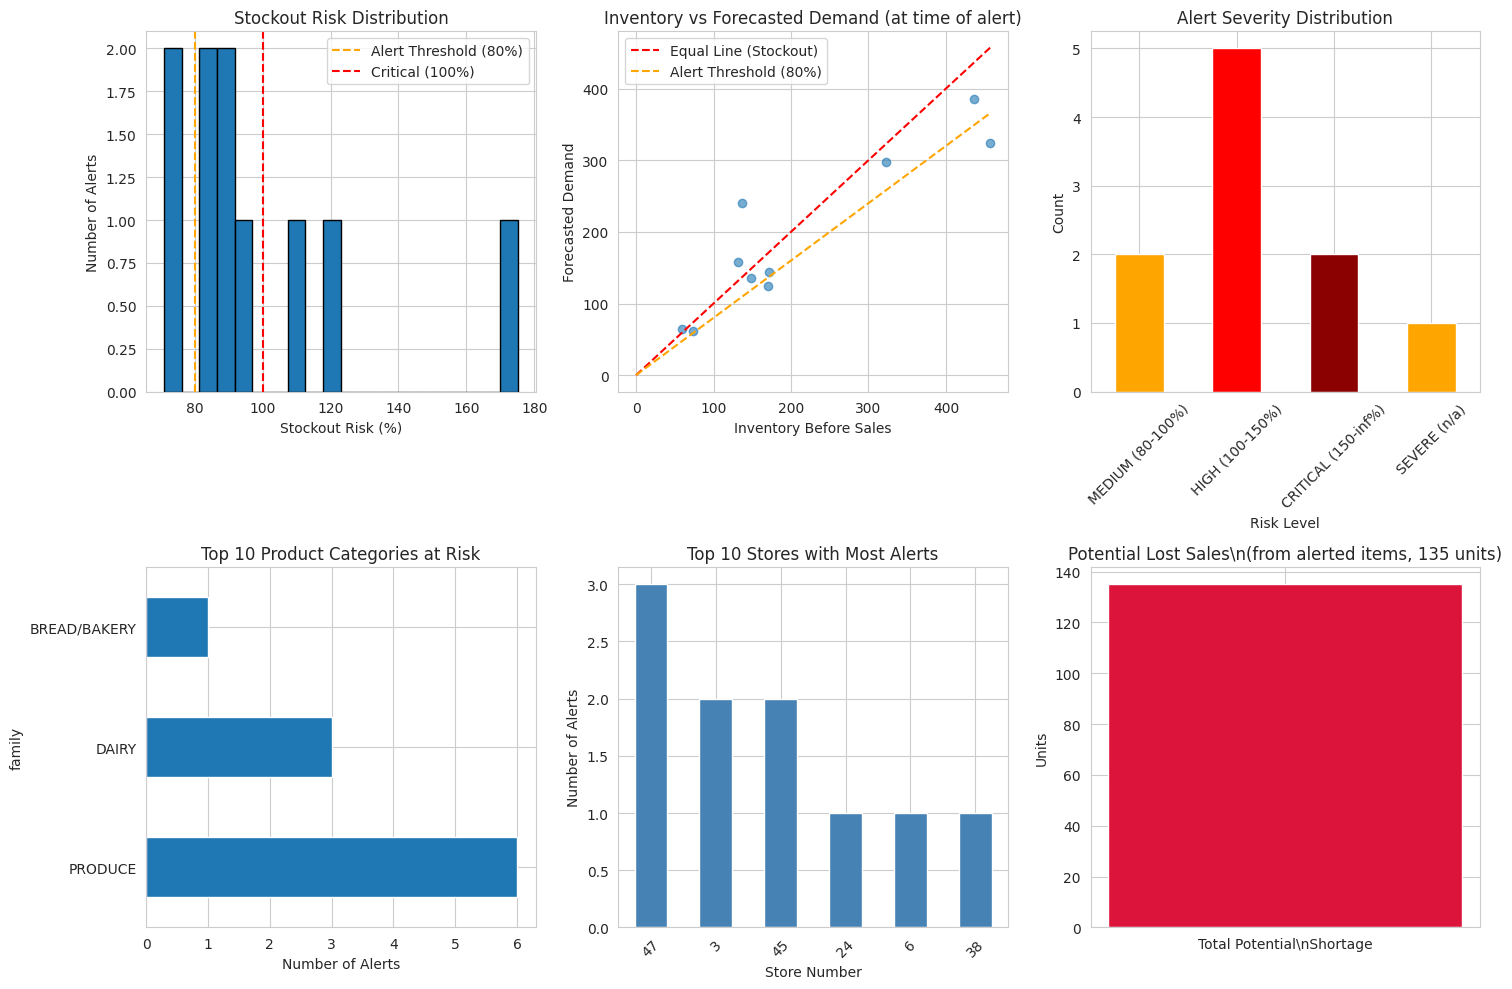

In [30]:
print("VISUALIZING ALERT INSIGHTS")

if not alerts_df.empty:
    # Set style
    sns.set_style("whitegrid")
    plt.figure(figsize=(15, 10))

    # 1. Stockout Risk Distribution
    plt.subplot(2, 3, 1)
    alerts_df['stockout_risk'].hist(bins=20, edgecolor='black')
    plt.xlabel('Stockout Risk (%)')
    plt.ylabel('Number of Alerts')
    plt.title('Stockout Risk Distribution')
    plt.axvline(x=80, color='orange', linestyle='--', label='Alert Threshold (80%)')
    plt.axvline(x=100, color='red', linestyle='--', label='Critical (100%)')
    plt.legend()

    # 2. Forecasted Demand vs Current Inventory
    plt.subplot(2, 3, 2)
    # Use inventory
    plt.scatter(alerts_df['inventory'], alerts_df['forecast'], alpha=0.6)
    max_val = max(alerts_df['inventory'].max(), alerts_df['forecast'].max())
    plt.plot([0, max_val], 
             [0, max_val], 
             'r--', label='Equal Line (Stockout)')
    plt.plot([0, max_val], 
             [0, max_val * 0.8], 
             '--', color='orange', label='Alert Threshold (80%)')
    plt.xlabel('Inventory Before Sales')
    plt.ylabel('Forecasted Demand')
    plt.title('Inventory vs Forecasted Demand (at time of alert)')
    plt.legend()

    # 3. Risk Level Distribution
    plt.subplot(2, 3, 3)
    alerts_df['risk_level'].value_counts().sort_index().plot(kind='bar', color=['orange', 'red', 'darkred'])
    plt.xlabel('Risk Level')
    plt.ylabel('Count')
    plt.title('Alert Severity Distribution')
    plt.xticks(rotation=45)

    # 4. Top Categories at Risk
    plt.subplot(2, 3, 4)
    top_categories = alerts_with_items['family'].value_counts().head(10)
    top_categories.plot(kind='barh')
    plt.xlabel('Number of Alerts')
    plt.title('Top 10 Product Categories at Risk')

    # 5. Store-wise Alert Distribution
    plt.subplot(2, 3, 5)
    store_alerts = alerts_df['store_nbr'].value_counts().head(10)
    store_alerts.plot(kind='bar', color='steelblue')
    plt.xlabel('Store Number')
    plt.ylabel('Number of Alerts')
    plt.title('Top 10 Stores with Most Alerts')
    plt.xticks(rotation=45)

    # 6. Potential Lost Sales
    plt.subplot(2, 3, 6)
    # 'potential_shortage' was calculated in the previous cell
    total_shortage = alerts_df['potential_shortage'].sum()
    plt.bar(['Total Potential\\nShortage'], [total_shortage], color='crimson')
    plt.ylabel('Units')
    plt.title(f'Potential Lost Sales\\n(from alerted items, {total_shortage:.0f} units)')

    plt.tight_layout()
    plt.savefig('alert_analysis_dynamic.png', dpi=300, bbox_inches='tight')
    plt.show()
else:
    print("Alerts DataFrame is empty. No visualizations to display.")